# Chapter 4. Training Models — Practice Notebook

## Linear Regression

Generating linear synthetic data using: $y = 4 + 3x + \text{Gaussian noise}$.

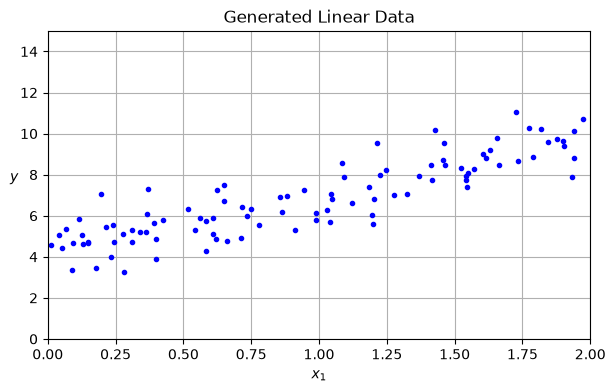

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

plt.figure(figsize=(7, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.title("Generated Linear Data")
plt.show()

**Output meaning:** A scattered cloud of 100 points trending upwards around the true line $y = 4 + 3x$. The noise keeps them from being perfectly aligned.

### The Normal Equation

Computing $\hat{\mathbf{\theta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$ directly in one step. We add $x_0 = 1$ to `X` for the bias term $\theta_0$.

In [3]:
X_b = np.c_[np.ones((100, 1)), X]  # add x0 = 1
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

print("Estimated theta_0 (intercept):", theta_best[0][0])
print("Estimated theta_1 (slope):    ", theta_best[1][0])

Estimated theta_0 (intercept): 4.21509615754675
Estimated theta_1 (slope):     2.7701133864384806


**Output meaning:** The model found $\theta_0 \approx 4.215$ and $\theta_1 \approx 2.770$ (very close to true $4$ and $3$). The slight difference is due to the random noise.

### Making Predictions with The Normal Equation

Predicting $y$ on new points ($x_1 = 0$ and $x_1 = 2$) and plotting the fitted line.

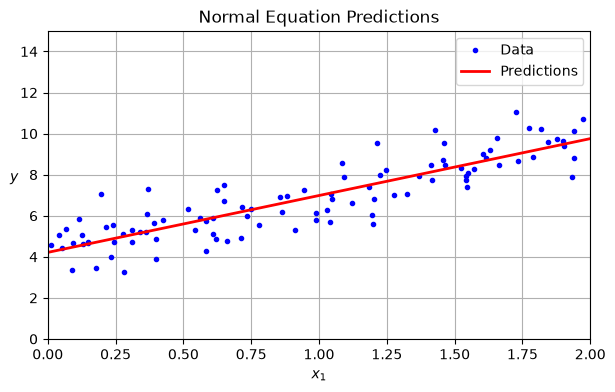

In [4]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
y_predict = X_new_b @ theta_best

plt.figure(figsize=(7, 4))
plt.plot(X, y, "b.", label="Data")
plt.plot(X_new, y_predict, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.legend()
plt.title("Normal Equation Predictions")
plt.show()

**Output meaning:** The red regression line cuts straight through the middle of the points, minimizing the Mean Squared Error (MSE).

### Computational Complexity & SVD Pseudoinverse

Scikit-Learn's `LinearRegression` uses SVD pseudoinverse ($\hat{\mathbf{\theta}} = \mathbf{X}^+ \mathbf{y}$) instead of inverting $(\mathbf{X}^T \mathbf{X})$ directly.

In [5]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)

print("Intercept (theta_0):", lin_reg.intercept_)
print("Slope (theta_1):    ", lin_reg.coef_)
print("Predictions on [0, 2]:\n", lin_reg.predict(X_new))

Intercept (theta_0): [4.21509616]
Slope (theta_1):     [[2.77011339]]
Predictions on [0, 2]:
 [[4.21509616]
 [9.75532293]]


In [6]:
# Direct SVD pseudoinverse via NumPy: theta = pinv(X_b) @ y
theta_svd = np.linalg.pinv(X_b) @ y
print("Theta via np.linalg.pinv:\n", theta_svd)

Theta via np.linalg.pinv:
 [[4.21509616]
 [2.77011339]]


**Output meaning:** Gives identical results to the Normal Equation, but SVD is faster ($\mathcal{O}(n^2)$ vs $\mathcal{O}(n^3)$) and never crashes if features are collinear (redundant).

---
## Gradient Descent

### Intuition: The Error Curve & Rolling Downhill
Before jumping into code loops, here is the core mental model from the book:
- For Linear Regression, the **Cost Function (MSE)** forms a convex U-shaped bowl.
- The bottom of the bowl is the **Global Minimum** (the optimal $\theta$ parameters with the lowest error).
- We start at a random $\theta$ (high on the bowl) and calculate the **gradient** (slope under our feet).
- We step in the **opposite direction** ($-\eta \times \text{gradient}$) downhill until error cannot get any smaller.

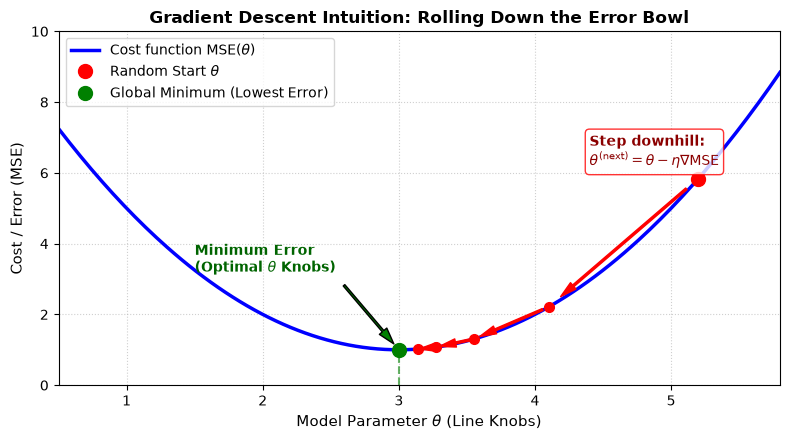

In [7]:
# Visualizing Gradient Descent rolling down the MSE error curve
theta_vals = np.linspace(0.5, 5.8, 200)
cost_vals = (theta_vals - 3)**2 + 1  # simulated convex MSE curve

plt.figure(figsize=(8, 4.5))
plt.plot(theta_vals, cost_vals, 'b-', linewidth=2.5, label='Cost function MSE($\\theta$)')

# Simulate Gradient Descent steps rolling down
thetas = [5.2]
eta = 0.25
for _ in range(4):
    grad = 2 * (thetas[-1] - 3)
    thetas.append(thetas[-1] - eta * grad)
costs = [(t - 3)**2 + 1 for t in thetas]

# Plot step arrows
for i in range(len(thetas) - 1):
    plt.annotate('', xy=(thetas[i+1], costs[i+1]), xytext=(thetas[i], costs[i]),
                 arrowprops=dict(facecolor='red', edgecolor='red', shrink=0.08, width=1.5, headwidth=6))

plt.plot(thetas, costs, 'ro', markersize=7)
plt.plot(thetas[0], costs[0], 'ro', markersize=10, label='Random Start $\\theta$')
plt.plot(3, 1, 'go', markersize=10, label='Global Minimum (Lowest Error)')
plt.vlines(3, 0, 1, linestyle='--', color='g', alpha=0.6)

plt.annotate('Minimum Error\n(Optimal $\\theta$ Knobs)',
             xy=(3, 1), xytext=(1.5, 3.2),
             arrowprops=dict(facecolor='green', shrink=0.08, width=1.5, headwidth=7),
             fontsize=10, fontweight='bold', color='darkgreen')

plt.text(4.4, 6.2, 'Step downhill:\n$\\theta^{(\\text{next})} = \\theta - \\eta \\nabla \\text{MSE}$',
         fontsize=10, fontweight='bold', color='darkred',
         bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='red', alpha=0.8))

plt.xlabel('Model Parameter $\\theta$ (Line Knobs)', fontsize=11)
plt.ylabel('Cost / Error (MSE)', fontsize=11)
plt.title('Gradient Descent Intuition: Rolling Down the Error Bowl', fontsize=12, fontweight='bold')
plt.ylim(0, 10)
plt.xlim(0.5, 5.8)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

**Key Takeaways from the Error Curve:**
1. **The Gradient** ($\nabla \text{MSE}$) always points **uphill** toward higher error.
2. **The Update Rule** subtracts the gradient ($\mathbf{\theta} - \eta \nabla$) to move **downhill**.
3. **Automatic Slowdown:** Notice how the red step arrows naturally get shorter as we near the bottom because the slope flattens (gradient $\to 0$).

### Batch Gradient Descent

Starting from random $\theta$, we compute the gradient over all 100 points and take 1000 steps downhill:
$$\mathbf{\theta}^{(\text{next})} = \mathbf{\theta} - \eta \frac{2}{m}\mathbf{X}_b^T(\mathbf{X}_b\mathbf{\theta} - \mathbf{y})$$

Final theta found by Batch GD:
 [[4.21509616]
 [2.77011339]]


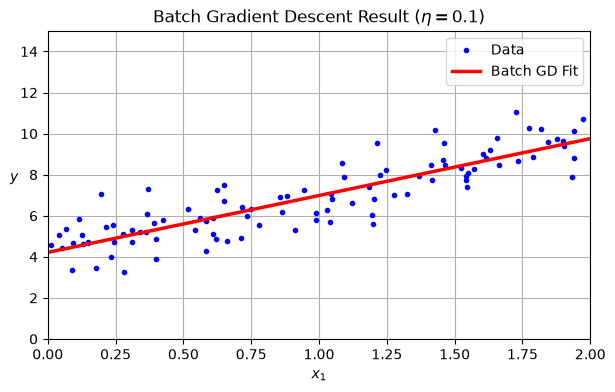

In [8]:
eta = 0.1  # learning rate
n_iterations = 1000
m = len(X_b)

# Random initialization
np.random.seed(42)
theta = np.random.randn(2, 1)

for iteration in range(n_iterations):
    gradients = 2/m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients

print("Final theta found by Batch GD:\n", theta)

# Predictions on [0, 2]
y_predict_bgd = X_new_b @ theta

# Plot fitted line
plt.figure(figsize=(7, 4))
plt.plot(X, y, "b.", label="Data")
plt.plot(X_new, y_predict_bgd, "r-", linewidth=2.5, label="Batch GD Fit")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.legend()
plt.title(r"Batch Gradient Descent Result ($\eta = 0.1$)")
plt.show()

**Output meaning:** Finds the exact same parameters ($\theta_0 \approx 4.215, \theta_1 \approx 2.770$) as the Normal Equation, but via 1,000 small downhill steps instead of inverting matrices.

### Visualizing the Effect of Learning Rate ($\eta$)

Here we plot the first 10 steps taken by Gradient Descent under 3 different learning rates:
- **Red dashed line**: Where the model started (random guess).
- **Blue solid lines**: The first 10 steps taken.

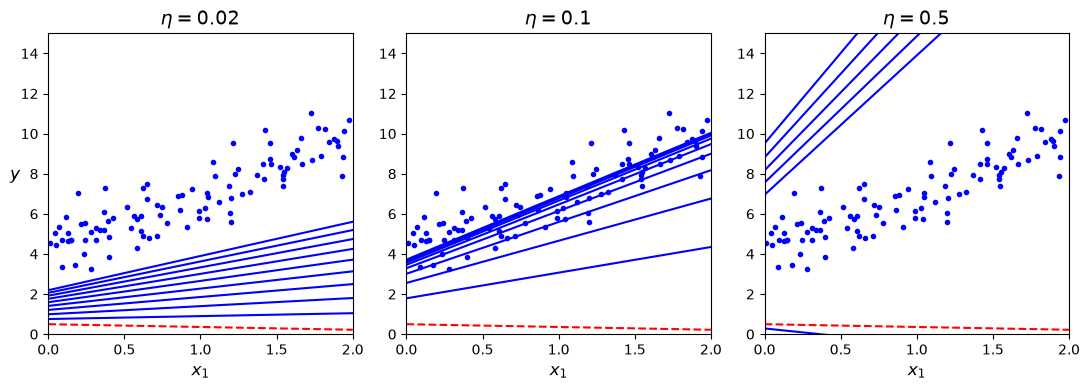

In [9]:
def plot_gradient_descent(theta, eta):
    m = len(X_b)
    plt.plot(X, y, "b.")
    n_iterations = 1000
    for iteration in range(n_iterations):
        if iteration < 10:
            y_predict = X_new_b @ theta
            style = "b-" if iteration > 0 else "r--"
            plt.plot(X_new, y_predict, style)
        gradients = 2/m * X_b.T @ (X_b @ theta - y)
        theta = theta - eta * gradients
    plt.xlabel("$x_1$", fontsize=12)
    plt.axis([0, 2, 0, 15])
    plt.title(fr"$\eta = {eta}$", fontsize=14)

np.random.seed(42)
theta_init = np.random.randn(2, 1)

plt.figure(figsize=(11, 4))
plt.subplot(131)
plot_gradient_descent(theta_init.copy(), eta=0.02)
plt.ylabel("$y$", rotation=0, fontsize=12)

plt.subplot(132)
plot_gradient_descent(theta_init.copy(), eta=0.1)

plt.subplot(133)
plot_gradient_descent(theta_init.copy(), eta=0.5)

plt.tight_layout()
plt.show()

**What the 3 plots show:**
- $\eta = 0.02$ (**Too small**): Barely moves; it will take thousands of iterations to reach the line.
- $\eta = 0.1$ (**Optimal**): In just 10 steps, the lines converge smoothly right onto the center of the points.
- $\eta = 0.5$ (**Too large**): Jumps wildly across the minimum and bounces out of the frame (diverging).

---
### Stochastic Gradient Descent (SGD)

Instead of using all 100 points, SGD picks **one random point** at each step.
A **learning schedule** gradually lowers the learning rate $\eta$ so it stops bouncing and settles near the minimum.

SGD Learned theta_0 (intercept): 4.210760113791362
SGD Learned theta_1 (slope):     2.7485607937881733


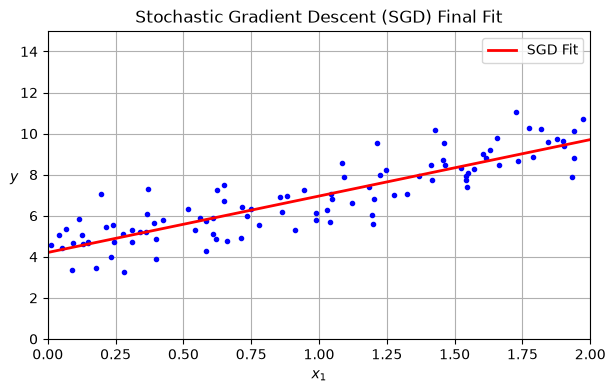

In [10]:
n_epochs = 50
t0, t1 = 5, 50  # learning schedule hyperparameters
m = len(X_b)

def learning_schedule(t):
    return t0 / (t + t1)

np.random.seed(42)
theta = np.random.randn(2, 1)  # random initialization

for epoch in range(n_epochs):
    for i in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index:random_index+1]
        yi = y[random_index:random_index+1]
        gradients = 2 * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(epoch * m + i)
        theta = theta - eta * gradients

print("SGD Learned theta_0 (intercept):", theta[0][0])
print("SGD Learned theta_1 (slope):    ", theta[1][0])

# Plot the final fitted line
plt.figure(figsize=(7, 4))
plt.plot(X, y, "b.")
plt.plot(X_new, X_new_b @ theta, "r-", linewidth=2, label="SGD Fit")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.legend()
plt.grid(True)
plt.title("Stochastic Gradient Descent (SGD) Final Fit")
plt.show()

**Output meaning:** The pure SGD loop finds $\theta_0 \approx 4.21$ and $\theta_1 \approx 2.75$ in just 50 epochs (compared to 1,000 iterations for Batch GD).
- **Core Takeaway:** SGD is much faster on large datasets because each step calculates the gradient on **only 1 random sample**.
- **Learning Schedule:** Because 1 sample is noisy, $\theta$ bounces around erratically. The schedule shrinks $\eta$ step by step so it gently settles at the optimal values.

### Scikit-Learn's `SGDRegressor` (Production Way)

In real projects, you don't write the loop by hand. Scikit-Learn provides `SGDRegressor`:

In [11]:
from sklearn.linear_model import SGDRegressor

# max_iter=1000 epochs, lr eta0=0.1, no regularization penalty
sgd_reg = SGDRegressor(max_iter=1000, tol=1e-3, penalty=None, eta0=0.1, random_state=42)
sgd_reg.fit(X, y.ravel())

print("SGDRegressor Intercept (theta_0):", sgd_reg.intercept_[0])
print("SGDRegressor Slope     (theta_1):", sgd_reg.coef_[0])

SGDRegressor Intercept (theta_0): 4.243652860329604
SGDRegressor Slope     (theta_1): 2.8250878043833314


**Output meaning:** In just 3 lines, `SGDRegressor` reaches $\theta_0 \approx 4.24$ and $\theta_1 \approx 2.82$. It runs extremely fast and handles massive datasets that do not fit in RAM.

## Polynomial Regression

When data has a non-linear relationship (e.g., curved or quadratic), a simple straight line will underfit. **Polynomial Regression** solves this by adding powers of each feature as new features, then training a standard **Linear Regression** model on this expanded feature set.

---

### Step-by-Step Approach:

1. **Inspect Non-Linear Data**:
   - Plot the dataset ($X$ vs $y$). If the points form a curve/parabola rather than a straight line, a standard linear model will have high bias (underfit).

2. **Feature Engineering with `PolynomialFeatures`**:
   - Import `PolynomialFeatures` from `sklearn.preprocessing`.
   - Instantiate: `poly_features = PolynomialFeatures(degree=2, include_bias=False)`.
     - `degree=2` adds $x^2$ (and interaction terms $x_1 x_2$ if multiple features exist).
     - `include_bias=False` prevents creating an extra column of $1$s because `LinearRegression` adds its own intercept ($	heta_0$) automatically.
   - Transform training data: `X_poly = poly_features.fit_transform(X)` (transforms $[x_1]$ into $[x_1, x_1^2]$).

3. **Train a Standard Linear Model**:
   - Fit `LinearRegression` on the expanded feature matrix:
     ```python
     lin_reg = LinearRegression()
     lin_reg.fit(X_poly, y)
     ```
   - The model learns the hypothesis: $\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_1^2$.

4. **Predict & Visualize (Smooth Curve)**:
   - **Generate a sorted grid**: `X_new = np.linspace(-3, 3, 100).reshape(100, 1)` (must be sorted so `matplotlib` connects points smoothly without zigzagging).
   - **Transform test points**: `X_new_poly = poly_features.transform(X_new)` (always use `.transform()`, **never** `.fit_transform()`, to reuse the training rules).
   - **Predict**: `y_new = lin_reg.predict(X_new_poly)`.
   - **Plot**: Display original points with `plt.plot(X, y, 'b.')` and the fitted polynomial curve with `plt.plot(X_new, y_new, 'r-')`.

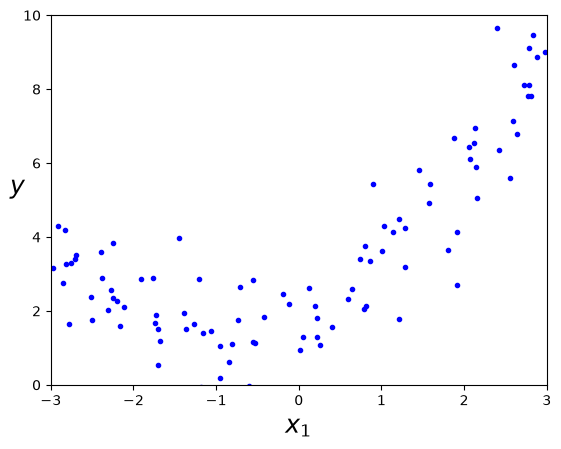

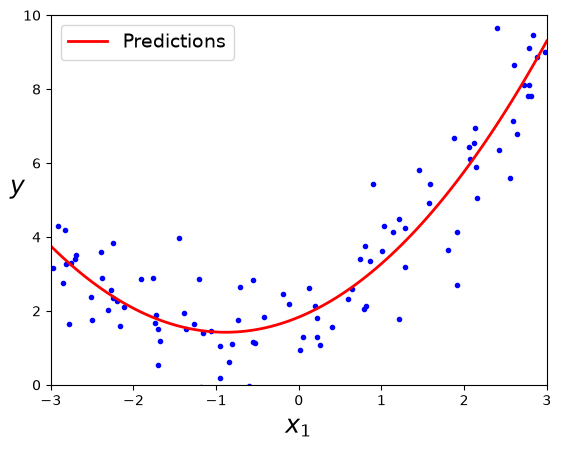

(array([1.83201261]), array([[0.92443887, 0.52185989]]))

In [24]:
# 1. Generate non-linear (quadratic) synthetic data: y = 0.5 * x^2 + x + 2 + noise
m = 100                                          # Number of data points
X = 6 * np.random.rand(m, 1) - 3                 # Random values in range [-3, 3]
y = 0.5 * X**2 + X + 2 + np.random.randn(m, 1)  # Quadratic formula with Gaussian noise added

# 2. Plot the raw generated points to inspect the curved pattern
plt.plot(X, y, "b.")                             # Plot training points as blue dots
plt.xlabel("$x_1$", fontsize=18)
plt.ylabel("$y$", rotation=0, fontsize=18)
plt.axis([-3, 3, 0, 10])                         # Set x-limits [-3, 3] and y-limits [0, 10]
# save_fig("quadratic_data_plot")
plt.show()

# 3. Add polynomial features (powers of each feature) to the dataset
from sklearn.preprocessing import PolynomialFeatures
poly_features = PolynomialFeatures(degree=2, include_bias=False) # include_bias=False because LinearRegression adds bias (theta_0) itself
X_poly = poly_features.fit_transform(X)         # Transforms X from [x1] -> [x1, x1^2]
X[0]                                            # First original instance: [x1]
X_poly[0]                                       # First transformed instance: [x1, x1^2]

# 4. Fit a standard Linear Regression model on the transformed features [x1, x1^2]
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)                          # Model learns: y_hat = theta_0 + theta_1 * x1 + theta_2 * x1^2
lin_reg.intercept_, lin_reg.coef_               # intercept_ is theta_0 (~2.0), coef_ are [theta_1 (~1.0), theta_2 (~0.5)]

# 5. Create a sorted, evenly spaced grid of points to draw a clean prediction curve
X_new = np.linspace(-3, 3, 100).reshape(100, 1) # 100 sorted points from -3 to 3 (sorted so matplotlib draws a smooth line, not a zigzag)
X_new_poly = poly_features.transform(X_new)     # Transform X_new to [x1, x1^2] (use .transform(), NOT fit_transform, to apply learned rules)
y_new = lin_reg.predict(X_new_poly)             # Calculate predictions: y_hat = theta_0 + theta_1 * x_new + theta_2 * (x_new)^2

# 6. Plot the original data points alongside the model's prediction curve
plt.plot(X, y, "b.")                             # Original noisy training data (blue dots)
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")  # Model predictions connected as a smooth red curve
plt.xlabel("$x_1$", fontsize=18)                # Label x-axis
plt.ylabel("$y$", rotation=0, fontsize=18)       # Label y-axis
plt.legend(loc="upper left", fontsize=14)        # Show legend in upper left corner
plt.axis([-3, 3, 0, 10])                         # Set plot axis limits
# save_fig("quadratic_predictions_plot")
plt.show()                                      # Display the final plot


## Learning Curves

**Learning curves** are plots of the model's performance (RMSE) on both the **training set** and the **validation set** as a function of the **training set size** (number of instances used for training).

They are used to diagnose whether a model is **underfitting**, **overfitting**, or **just right**.

---

### How to Read This Plot (A Classic Underfitting Model):

1. **Training Error (Red `+` line)**:
   - **Starts at 0**: When the model is trained on only 1 or 2 points, a line can fit them perfectly.
   - **Rises as data is added**: As more instances arrive, noise and non-linearity make it impossible for a straight line to fit every point perfectly.
   - **Reaches a plateau**: Adding more instances no longer changes the average error.

2. **Validation Error (Blue line)**:
   - **Starts very high**: When trained on just 1 or 2 points, the model generalizes terribly to unseen data.
   - **Decreases gradually**: As the model sees more examples, it learns the general trend.
   - **Reaches a plateau**: Because a straight line cannot capture quadratic curves, the error plateaus at a high RMSE, very close to the training curve.

> **Key Takeaway (Underfitting Signature)**: Both curves reach a **plateau**, they are **fairly close together**, and the error is **high**. If a model is underfitting, **adding more training data will NOT help** — you need a more complex model (e.g., polynomial) or better features.

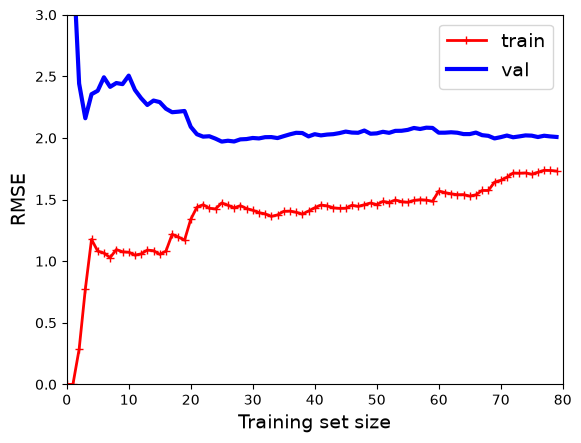

In [26]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

def plot_learning_curves(model, X, y):
    # 1. Split data into 80% training and 20% validation
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=10)
    train_errors, val_errors = [], []
    
    # 2. Train the model iteratively with expanding training set sizes (from 1 instance to all instances)
    for m in range(1, len(X_train) + 1):
        model.fit(X_train[:m], y_train[:m])                           # Train on first m instances only
        y_train_predict = model.predict(X_train[:m])                  # Predict on those same m training instances
        y_val_predict = model.predict(X_val)                          # Predict on the full validation set
        train_errors.append(mean_squared_error(y_train[:m], y_train_predict))
        val_errors.append(mean_squared_error(y_val, y_val_predict))

    # 3. Plot RMSE (Root Mean Squared Error) for both training and validation sets
    plt.plot(np.sqrt(train_errors), "r-+", linewidth=2, label="train") # Red '+' curve: training error
    plt.plot(np.sqrt(val_errors), "b-", linewidth=3, label="val")      # Blue curve: validation error
    plt.legend(loc="upper right", fontsize=14)
    plt.xlabel("Training set size", fontsize=14)
    plt.ylabel("RMSE", fontsize=14)

# 4. Fit a simple linear model on non-linear data to visualize classic underfitting
lin_reg = LinearRegression()
plot_learning_curves(lin_reg, X, y)
plt.axis([0, 80, 0, 3])                         # Set axis ranges: x from 0 to 80, y (RMSE) from 0 to 3
# save_fig("underfitting_learning_curves_plot")
plt.show()


### 10th-Degree Polynomial Learning Curves (Overfitting)

Fitting a complex degree-10 polynomial (Figure 4-16) shows the **overfitting signature**:
* **Much lower training error**: The flexible model fits training points closely.
* **Gap between curves**: Training error is significantly lower than validation error (high variance).
* **Fix**: Add **more training data** (curves will converge) or **regularize** the model.


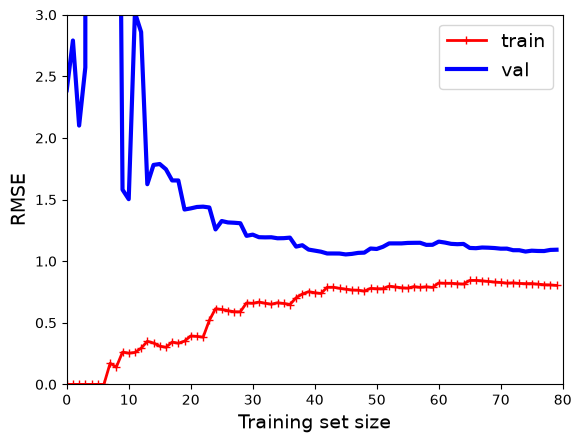

In [27]:
from sklearn.pipeline import Pipeline

polynomial_regression = Pipeline([
    ("poly_features", PolynomialFeatures(degree=10, include_bias=False)),
    ("lin_reg", LinearRegression()),
])

plot_learning_curves(polynomial_regression, X, y)
plt.axis([0, 80, 0, 3])
plt.show()


## Regularized Linear Models — Ridge Regression

Ridge Regression (also called *Tikhonov regularization*) is a regularized version of Linear Regression where a penalty term equal to $\alpha \sum_{i=1}^n \theta_i^2$ is added to the cost function:
$$J(\mathbf{\theta}) = \text{MSE}(\mathbf{\theta}) + \alpha \frac{1}{2} \sum_{i=1}^n \theta_i^2$$

This forces the learning algorithm not only to fit the data, but also to keep model weights $\mathbf{\theta}$ as small as possible. The hyperparameter $\alpha$ controls how much you want to regularize the model:
* If $\alpha = 0$, Ridge Regression is just standard Linear Regression.
* If $\alpha$ is very large, all weights end up very close to zero, resulting in a flat line through the data's mean.

> **Note:** Ridge Regression is sensitive to the scale of input features, so it is critical to scale the data (e.g., using `StandardScaler`) before training.

Cholesky prediction at x=1.5: 1.5507146455432228
SAG prediction at x=1.5:      1.5507218858402763


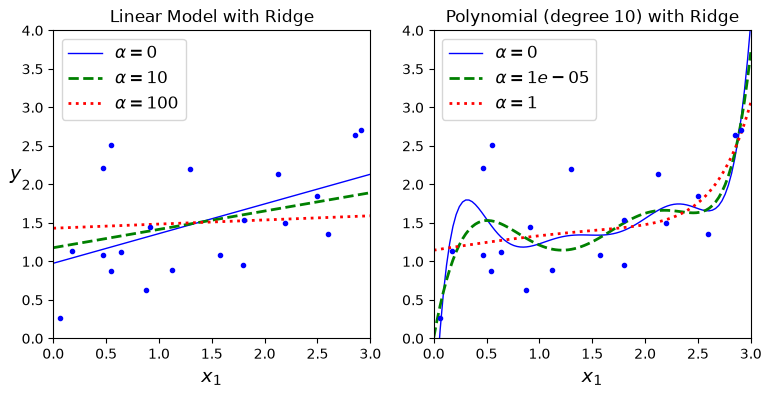

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# 1. Generate small noisy dataset
np.random.seed(42)
m = 20
X = 3 * np.random.rand(m, 1)
y = 1 + 0.5 * X + np.random.randn(m, 1) / 1.5
X_new = np.linspace(0, 3, 100).reshape(100, 1)

# 2. Closed-form solution (Cholesky solver) vs. Iterative (SAG solver)
ridge_reg = Ridge(alpha=1, solver="cholesky", random_state=42)
ridge_reg.fit(X, y)
print("Cholesky prediction at x=1.5:", ridge_reg.predict([[1.5]])[0][0])

ridge_reg_sag = Ridge(alpha=1, solver="sag", random_state=42)
ridge_reg_sag.fit(X, y)
print("SAG prediction at x=1.5:     ", ridge_reg_sag.predict([[1.5]])[0][0])


# 3. Plotting helper for Figure 4-17 (varying alpha on linear vs. polynomial)
def plot_model(model_class, polynomial, alphas, **model_kargs):
    for alpha, style in zip(alphas, ("b-", "g--", "r:")):
        model = model_class(alpha, **model_kargs) if alpha > 0 else LinearRegression()
        if polynomial:
            model = Pipeline([
                ("poly_features", PolynomialFeatures(degree=10, include_bias=False)),
                ("std_scaler", StandardScaler()),
                ("regul_reg", model),
            ])
        model.fit(X, y)
        y_new_regul = model.predict(X_new)
        lw = 2 if alpha > 0 else 1
        plt.plot(X_new, y_new_regul, style, linewidth=lw, label=rf"$\alpha = {alpha}$")
    plt.plot(X, y, "b.", linewidth=3)
    plt.legend(loc="upper left", fontsize=12)
    plt.xlabel("$x_1$", fontsize=14)
    plt.axis([0, 3, 0, 4])


plt.figure(figsize=(9, 4))
plt.subplot(121)
plot_model(Ridge, polynomial=False, alphas=(0, 10, 100), random_state=42)
plt.ylabel("$y$", rotation=0, fontsize=14)
plt.title("Linear Model with Ridge")

plt.subplot(122)
plot_model(Ridge, polynomial=True, alphas=(0, 10**-5, 1), random_state=42)
plt.title("Polynomial (degree 10) with Ridge")

plt.show()


**Output meaning (Figure 4-17):**
* **Left Plot (Linear Model with Ridge)**:
  - $\alpha = 0$ (Blue solid): Standard linear regression without regularization; fits the steepest slope.
  - $\alpha = 10$ (Green dashed): Moderate penalty shrinks the slope $\theta_1$, making the line flatter.
  - $\alpha = 100$ (Red dotted): Strong penalty crushes weights close to $0$; the line becomes almost completely flat (predicting close to the mean $\bar{y}$).
* **Right Plot (10th-Degree Polynomial Model with Ridge)**:
  - $\alpha = 0$ (Blue solid): High-degree polynomial without regularization **overfits wildly**, oscillating through noise (high variance).
  - $\alpha = 10^{-5}$ (Green dashed): Even a tiny penalty tames the oscillations into a smooth, well-generalizing curve.
  - $\alpha = 1$ (Red dotted): Strong penalty heavily squashes higher-degree coefficients, turning the complex polynomial into a simple, near-linear line.
* **Key Takeaway**: Increasing $\alpha$ shrinks weights $\implies$ reduces model complexity and variance (combats overfitting), but increases bias.

## Lasso Regression

Lasso (Least Absolute Shrinkage and Selection Operator) Regression adds an $\ell_1$ penalty ($\alpha \sum_{i=1}^n |\theta_i|$) to the cost function instead of an $\ell_2$ penalty. This forces the model to perform automatic feature selection by driving the weights of the least important features completely to zero.

Lasso prediction at x=1.5: 1.5378817442675206


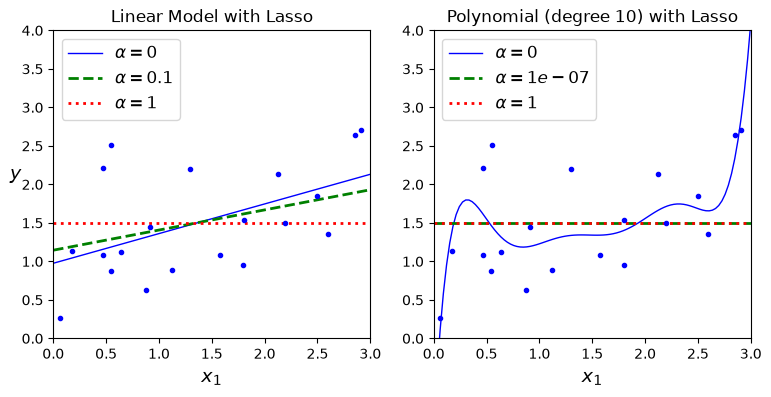

In [29]:
from sklearn.linear_model import Lasso

# 1. Quick Lasso prediction
lasso_reg = Lasso(alpha=0.1, random_state=42)
lasso_reg.fit(X, y)
print("Lasso prediction at x=1.5:", lasso_reg.predict([[1.5]])[0][0])

# 2. Plot Figure 4-18 (Linear vs. 10th-Degree Polynomial with Lasso)
plt.figure(figsize=(9, 4))

plt.subplot(121)
plot_model(Lasso, polynomial=False, alphas=(0, 0.1, 1), random_state=42)
plt.ylabel("$y$", rotation=0, fontsize=14)
plt.title("Linear Model with Lasso")

plt.subplot(122)
plot_model(Lasso, polynomial=True, alphas=(0, 10**-7, 1), random_state=42, tol=1)
plt.title("Polynomial (degree 10) with Lasso")

# save_fig("lasso_regression_plot")
plt.show()


**Output meaning & Lasso vs. Ridge:**
* **Automatic Feature Selection**: In the right plot, notice how $\alpha = 10^{-7}$ and $\alpha = 1$ look almost linear/quadratic — Lasso drove the weights of the higher-degree polynomial features ($x^3, x^4, \dots$) completely to zero, producing a **sparse model**.
* **Key Difference (Lasso vs. Ridge)**:
  - **Ridge ($\ell_2$)**: Shrinks weights close to zero, keeping *all* features (ideal when most features are useful).
  - **Lasso ($\ell_1$)**: Shrinks weights all the way to **exact zero**, effectively dropping useless features (ideal when only a few features actually matter).

## Elastic Net

Elastic Net is a middle ground between Ridge and Lasso Regression that blends both penalties together using the `l1_ratio`:
* `l1_ratio = 0`: Exactly equivalent to Ridge Regression.
* `l1_ratio = 1`: Exactly equivalent to Lasso Regression.

> **When to prefer Elastic Net over Lasso?** Ridge is generally the best default. But if you suspect only a few features matter, you should prefer Lasso or Elastic Net. Elastic Net is generally preferred over Lasso because Lasso can behave erratically when several features are strongly correlated or when features outnumber training instances.

In [30]:
from sklearn.linear_model import ElasticNet

elastic_net = ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42)
elastic_net.fit(X, y)
print("Elastic Net prediction at x=1.5:", elastic_net.predict([[1.5]])[0])


Elastic Net prediction at x=1.5: 1.5433323205813605
